# ESTOC 2025

This script is using a sample from the ERA5--Drought data set from the European Centre for Medium-range Weather Forecasts (ECMWF) and plots a map for selected countries.
> Keune, J., F. Di Giuseppe, C. Barnard, E. Damasio da Costa, and F. Wetterhall (2025): ERA5--Drought: Global drought indicators based on ECMWF reanalysis. Sci Data 12, 616 (2025). https://doi.org/10.1038/s41597-025-04896-y.

## Setup and Settings

#### Load libraries

In [1]:
import os 
import sys
import math
import datetime as dt
import pandas as pd
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import geopandas as gpd
import fiona
import regionmask
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import matplotlib.patches as mpatches
import string
from dateutil import relativedelta
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

#### Some helpful functions

In [2]:
EARTHRADIUS = 6371  # earth radius [km]
def calculate_gridarea(lats_centr, res, nlon):

    lats1 = (lats_centr + (res / 2)) * np.pi / 180  # np.sin requires radians
    lats2 = (lats_centr - (res / 2)) * np.pi / 180
    areas = (
        (np.pi / 180) * (EARTHRADIUS ** 2) * np.abs(np.sin(lats1) - np.sin(lats2)) * res
    )

    ## overwrite any areas of 0 (at the poles) with np.NaN to prevent problems
    areas[np.where(areas == 0.0)] = np.nan
    # return array of dimension nlat x nlon
    area_2d = np.swapaxes(np.tile(areas, (nlon, 1)), 0, 1)
    return area_2d

#### General settings

In [3]:
ref_syyyy = 1991
ref_eyyyy = 2020
yyyy_start= 1980
yyyy_end  = 2026
#indicator = "SPEI"
indicator = "SPI"
window    = 1
yyyy      = 2025
mm        = "07"
dataset   = "era5"
stream    = "moda"
#distribut = "genlogistic"
distribut = "gamma"
# new versions
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#%{yyyy}{mm}01/hr"
#ipath_era5t= f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#{yyyy}{mm}01/hr"
lpath     = "/ec/vol/centaur/nejk/drought_monitor"
country   = ["Norway","Sweden","Finland"]

In [4]:
dates = pd.date_range(start=f"{yyyy_start}-01-01",end=f"{yyyy_end}-01-01", freq='ME')#[:-8]
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]
print(dates)
print(dates.size)

DatetimeIndex(['1980-01-31', '1980-02-29', '1980-03-31', '1980-04-30',
               '1980-05-31', '1980-06-30', '1980-07-31', '1980-08-31',
               '1980-09-30', '1980-10-31',
               ...
               '2025-03-31', '2025-04-30', '2025-05-31', '2025-06-30',
               '2025-07-31', '2025-08-31', '2025-09-30', '2025-10-31',
               '2025-11-30', '2025-12-31'],
              dtype='datetime64[ns]', length=552, freq='ME')
552


### Landmask and area

In [5]:
# binary land mask
lfile      = f"{lpath}/landmask_era5_global.nc"
lmask      = xr.open_dataset(lfile)['lsm']
lmask      = lmask.where( lmask.values == 1 ) # set 0s to nan
# land fraction
lffile     = f"{lpath}/landmask_era5_global_frac.nc"
lmask_frac = xr.open_dataset(lffile)['var172']

/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.42.0 or higher is recommended. You are running version 2.31.0
  warnings.warn(


### Country / Region of interest

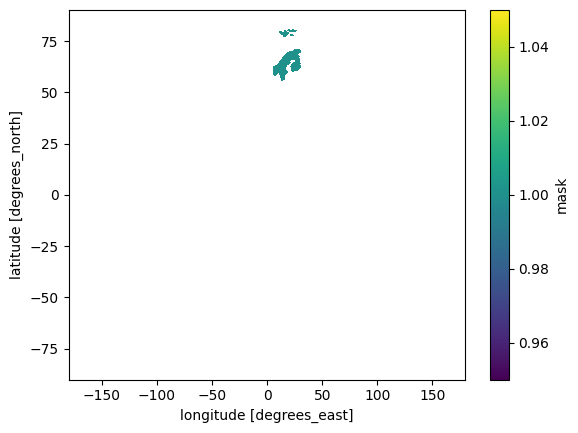

In [6]:
#regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].plot()
mask = regionmask.defined_regions.natural_earth_v5_0_0.countries_110[["Norway","Sweden","Finland"]].mask(lmask.lon, lmask.lat)
mask = xr.where(np.isnan(mask), np.nan, 1)
mask.plot()

In [7]:
lon1 = 4  #math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][0])
lon2 = 32 #math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][2])
lat1 = 54 #math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][1])
lat2 = 72 #math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][3])
print(f"Bounding box: lats {lat1} to {lat2}, lons {lon1} to {lon2}")

# surrounding for slice, to avoid cut offs
n=5


# or choose manual bounding box: 
# Horn of Africa: Somalia, Ethiopia, Kenya
#ax.set_xlim([32,52])
#ax.set_ylim([-5,18])
#lon1 = 32
#lon2 = 52
#lat1 = -5
#lat2 = 18

Bounding box: lats 54 to 72, lons 4 to 32


## Drought indices

### Read drought index 

In [8]:
filedate_seq = [dt.datetime.strftime(i, "%Y%m01") for i in pdate_seq[window:]]
filelist = []
for idate in filedate_seq:
    # /ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/
    ifile = f"{ipath}/era5/{idate}/hr/{indicator}{window}_{distribut}_global_era5_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
    if os.path.exists(ifile):
        filelist.append(ifile)
    else:
        ifile = f"{ipath}/era5t/{idate}/hr/{indicator}{window}_{distribut}_global_era5t_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
        filelist.append(ifile)
print(filelist[:20])

drought_index = {}
drought_index[window] = xr.open_mfdataset(filelist).sel(lon=slice(lon1-n, lon2+n), lat=slice(lat2+n, lat1-n))
drought_index[window] = xr.where(drought_index[window] == -9999, np.nan, drought_index[window])
print(drought_index[window])

# read barren area mask
vfile = "/home/nejk/code/dryfall_oper/helpers_oper/barren_mask.nc"
bmask = xr.open_dataset(vfile)
drought_index[window] = xr.where( (bmask['barren_mask'][0,:,:] == 1) & (~np.isnan(drought_index[window])) , -9999, drought_index[window])

['/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19800201/hr/SPI1_gamma_global_era5_moda_ref1991to2020_198002.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19800301/hr/SPI1_gamma_global_era5_moda_ref1991to2020_198003.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19800401/hr/SPI1_gamma_global_era5_moda_ref1991to2020_198004.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19800501/hr/SPI1_gamma_global_era5_moda_ref1991to2020_198005.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19800601/hr/SPI1_gamma_global_era5_moda_ref1991to2020_198006.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19800701/hr/SPI1_gamma_global_era5_moda_ref1991to2020_198007.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/19800801/hr/SPI1_gamma_global_era5_moda_ref1991to2020_198008.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/

### Plot summer maps

/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


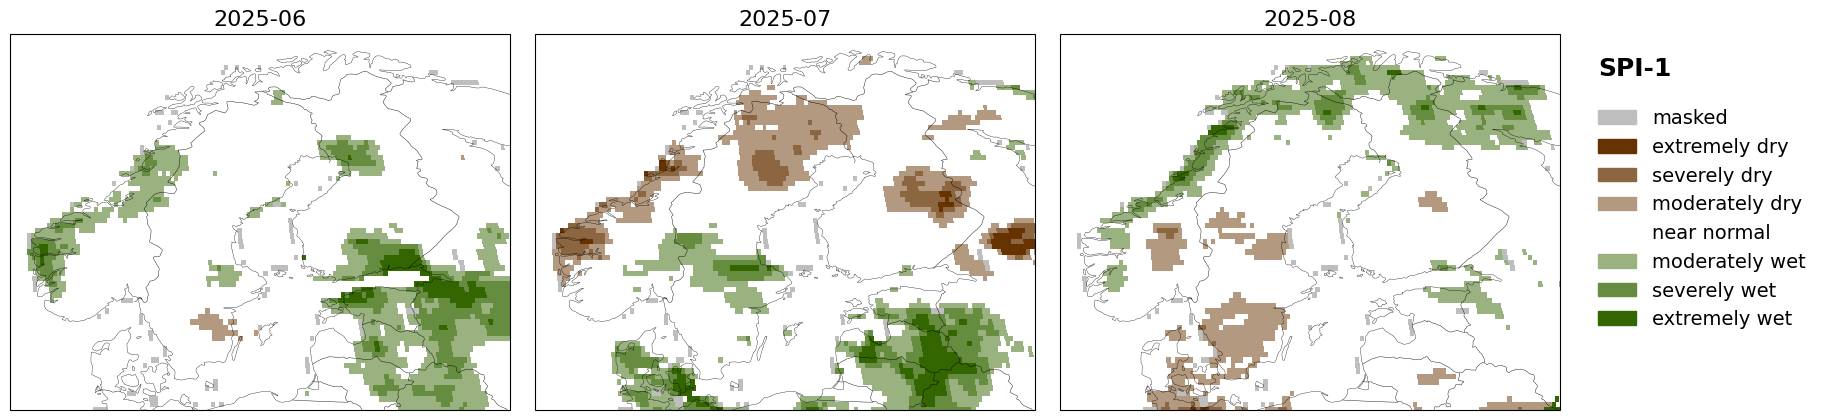

In [9]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]


n = 3
istart = np.where(drought_index[window].time.dt.strftime("%Y-%m") == "2025-06")[0][0]

fig, axes = plt.subplots(
    1, n,
    figsize=(20, 6),
    subplot_kw={"projection": ccrs.Robinson()}
)

plt.subplots_adjust(wspace=0.05)
fig.suptitle(f"{indicator}-{window}", fontsize=18, y=0.77, x=0.9375, fontweight="bold")

for itime, ax in enumerate(axes):

    toplot = drought_index[window].isel(time=istart + itime)[f"{indicator}{window}"]
    datestr = str(toplot.time.values)[0:7]

    ax.coastlines(color="black", lw=0.25)
    ax.add_feature(cartopy.feature.BORDERS, color="black", lw=0.3)
    ax.set_extent([lon1, lon2, lat1, lat2], crs=ccrs.PlateCarree())


    toplot.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        x="lon",
        y="lat",
        add_colorbar=False,
        colors=mycollisthex,
        levels=mylevels
    )

    ax.set_title(datestr, fontsize=16)

# add legend
legend_patches = [
    mpatches.Patch(color=mycollisthex[i], label=legnames[i])
    for i in range(len(legnames))
]
fig.legend(
    handles=legend_patches,
    loc="center left",
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    fontsize=14
)

plt.savefig(
    f"figures/Fennoscandia_map_{indicator}{window}_JJA_2025_subplots.png",
    dpi=300,
    transparent=True,
    pad_inches=0.1
)

plt.show()

## Country specific information

### Mask drought index

ValueError: operands could not be broadcast together with shapes (113,153) (97,137) 

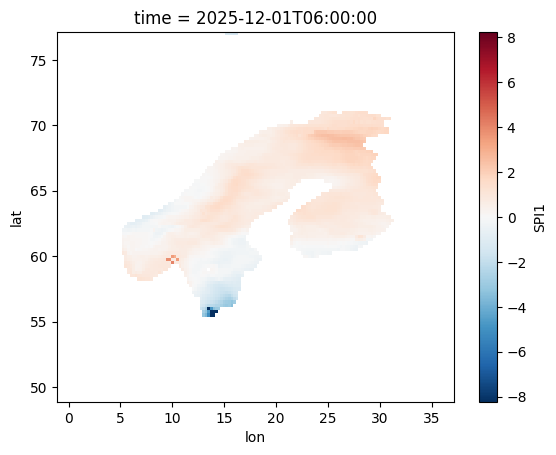

In [10]:
masked_drought_index = drought_index[window] * mask
masked_drought_index = xr.where(masked_drought_index == -9999, np.nan, masked_drought_index)
masked_drought_index.isel(time=-1)[f'{indicator}{window}'].plot()

area_2d = calculate_gridarea(masked_drought_index.lat, res=abs(masked_drought_index.lat[1]-masked_drought_index.lat[0]), nlon=len(masked_drought_index.lon))*lmask.sel(lon=slice(lon1-n, lon2+n), lat=slice(lat2+n, lat1-n))[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': masked_drought_index.lat,'lon': masked_drought_index.lon}, dims=["lat", "lon"])
area_2d_adj = area_2d * lmask_frac.sel(lon=slice(lon1-n, lon2+n), lat=slice(lat2+n, lat1-n))
area_2d_adj = area_2d_adj.where( area_2d_adj.values != 0 ) # set 0s to nan
mask_cut = mask.sel(lon=slice(lon1-n, lon2+n), lat=slice(lat2+n, lat1-n))
#area_2d.plot()
#area_2d_adj.plot()

### Calculate area in drought

In [ ]:
#robinson = ccrs.Robinson().proj4_init

In [ ]:
# calculate area in drought
area_3d_adj = area_2d_adj.reindex_like(masked_drought_index, method="nearest")
aid = {}

swindow=f"w{window}"
aid[swindow] = {}

for severity in ['moderate','severe','extreme','any']:
        
    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = -1

    rdi = masked_drought_index[f'{indicator}{window}']
    dmask  = xr.where((rdi > thresh_min) & (rdi <= thresh_max) & (rdi != -9999), 1, np.nan)
    tmp    = 100 * (dmask*area_3d_adj).sum(dim=["lat", "lon"]) / (mask_cut*area_3d_adj).sum(dim=["lat", "lon"])
    aid[swindow][severity] = tmp.to_pandas() 

    del(tmp, dmask)

### Plot timeseries of area in drought

In [ ]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

In [ ]:
fig, ax1 = plt.subplots(1,1, figsize=(12,4))
#title1 = r"$\bf{" + f"{string.ascii_lowercase[0]}" + "}$"
#fig.suptitle(f"{title1} | Percent of {country} in drought ({indicator}-{window})", fontsize=22)
#fig.suptitle(f"Area of {country} in long-term drought ({indicator}-{window})", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 20}
plt.rc('font', **font)

severities = ['extreme','severe','moderate']
pidata2 = aid[f'w{window}']['extreme']#[f'{indicator}{window}']
pidata3 = aid[f'w{window}']['severe']#[f'{indicator}{window}']
pidata4 = aid[f'w{window}']['moderate']#[f'{indicator}{window}']
apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
#apidata.index = apidata.index.shift(-(window-1), freq="MS") # shift datetimeindex to get start date
bottom = np.zeros(len(apidata.index))
for i in range(len(apidata.columns)):
    p = ax1.bar(apidata.index, apidata.iloc[:,i], facecolor=mycollisthex[i+1], 
                alpha=1, 
                width=relativedelta.relativedelta(months=1), 
                label=severities[i], 
                bottom=bottom,
                align='edge')
    bottom += apidata.iloc[:,i]
#ax1.set_ylabel("Area in drought [%]", size=18)
#ax1.legend(ncol=3, loc='upper center', fancybox=False, shadow=False, reverse=True, fontsize=12)
ax1.margins(x=0)
#ax1.spines['top'].set_visible(False)
#ax1.spines['right'].set_visible(False)
#ax1.spines['left'].set_visible(False)
#ax1.tick_params(axis='y', colors='dimgray')
#ax1.tick_params(axis='y', colors='dimgray')
ax1.tick_params(axis='x', colors='black')
#ax1.xaxis.label.set_color('None')
#ax1.yaxis.label.set_color('None')
ax1.minorticks_on()
ax1.xaxis.set_minor_locator(AutoMinorLocator(10))
# Major ticks every 20, minor ticks every 5
#https://stackoverflow.com/questions/24943991/change-grid-interval-and-specify-tick-labels
major_ticks = np.arange(0, 150, 50)
minor_ticks = np.arange(0, 150, 10)
ax1.set_yticks(major_ticks)
ax1.set_yticks(minor_ticks, minor=True)
ax1.yaxis.tick_right()
ax1.xaxis.tick_bottom()
# And a corresponding grid
#ax1.grid(which='minor')
# Or if you want different settings for the grids:
#ax.grid(which='minor', alpha=0.2)
#ax.grid(which='major', alpha=0.5)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=12)
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(which='major', alpha=0.5, color='gray', linestyle='solid', zorder=3) #dashed
ax1.yaxis.grid(which='minor', alpha=0.2, color='lightgray', linestyle='solid', zorder=3) #dashed
ax1.set_ylim([0,105])
#for tick in ax1.get_xticklabels():
#    tick.set_rotation(45)
    
plt.savefig(f"figures/Fennoscandia_{indicator}{window}_AID_timeseries_monthly.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()

### Plot maps for summer months

In [ ]:
n = 3
istart = np.where(apidata.index.strftime("%Y-%m") == "2025-06")[0][0]

fig, axes = plt.subplots(
    1, n,
    figsize=(20, 6),
    subplot_kw={"projection": ccrs.Robinson()}
)

plt.subplots_adjust(wspace=0.05)
fig.suptitle(f"{indicator}-{window}", fontsize=18, y=0.77, x=0.9375, fontweight="bold")

for itime, ax in enumerate(axes):

    toplot = drought_index[window].isel(time=istart + itime)[f"{indicator}{window}"]
    print(toplot.time.values)
    datestr = str(toplot.time.values)[0:7]

    ax.coastlines(color="black", lw=0.25)
    ax.add_feature(cartopy.feature.BORDERS, color="black", lw=0.3)

    toplot.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        x="lon",
        y="lat",
        add_colorbar=False,
        colors=mycollisthex,
        levels=mylevels
    )

    ax.set_title(datestr, fontsize=16)

# optional: add one shared colorbar
import matplotlib.patches as mpatches
# Build classification legend
legend_patches = [
    mpatches.Patch(color=mycollisthex[i], label=legnames[i])
    for i in range(len(legnames))
]
fig.legend(
    handles=legend_patches,
    loc="center left",
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    fontsize=14
)
#fig.title(f"{indicator}{window}", fontsize=16)

plt.savefig(
    f"figures/Fennoscandia_map_{indicator}{window}_JJA_2025_subplots.png",
    dpi=300,
    transparent=True,
    pad_inches=0.1
)

plt.show()


## Fire Weather Index

In [13]:
import cdsapi

dataset = "cems-fire-historical-v1"
request = {
    "product_type": "reanalysis",
    "variable": ["fire_weather_index"],
    "dataset_type": "consolidated_dataset",
    "system_version": ["4_1"],
    #"year": ["2025"],
    #"month": ["06", "07", "08"],
    "year": ["1991", "1992",
        "1993", "1994", "1995",
        "1996", "1997", "1998",
        "1999", "2000", "2001",
        "2002", "2003", "2004",
        "2005", "2006", "2007",
        "2008", "2009", "2010",
        "2011", "2012", "2013",
        "2014", "2015", "2016",
        "2017", "2018", "2019",
        "2020", "2021", "2022",
        "2023", "2024", "2025"
    ],
    "month": ["07"],
    "day": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12",
        "13", "14", "15",
        "16", "17", "18",
        "19", "20", "21",
        "22", "23", "24",
        "25", "26", "27",
        "28", "29", "30",
        "31"
    ],
    "grid": "0.25/0.25",
    "data_format": "netcdf"
    #"area": [71, -25, 35, 66], # N, W, S, E
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2026-01-22 12:17:44,301 INFO Request ID is a864a52e-3bd4-4975-a27a-6166abc55511
2026-01-22 12:17:44,342 INFO status has been updated to accepted
2026-01-22 12:18:05,425 INFO status has been updated to running
2026-01-22 12:24:02,626 INFO status has been updated to successful


9f02e72d688209a604f921af3b12af2a.nc:   0%|          | 0.00/568M [00:00<?, ?B/s]

'9f02e72d688209a604f921af3b12af2a.nc'

In [15]:
ncfile = "fwi_july_2025_max.nc"
fwi_max = xr.open_dataset(ncfile).sel(longitude=slice(lon1-n, lon2+n), latitude=slice(lat2+n, lat1-n))

/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


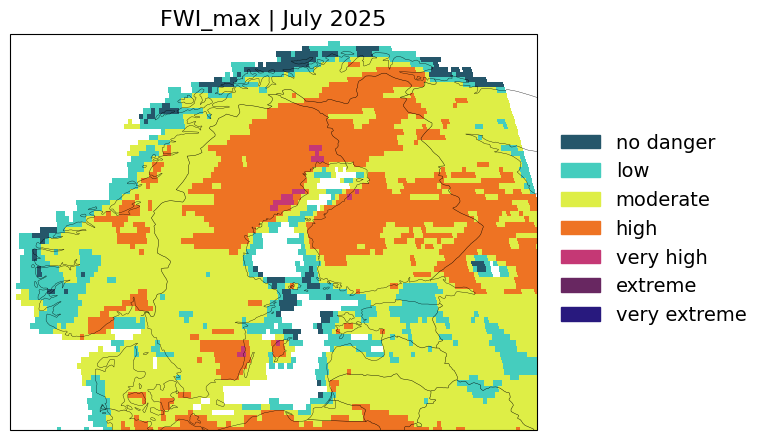

In [31]:
#mylevels     = [0,10,20,30]
#mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
#legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

#Sehr geringe Gefahr: FWI ist weniger als 5.2. 
#Geringe Gefahr: FWI liegt zwischen 5.2 und 11.2. 
#Mäßige Gefahr: FWI liegt zwischen 11.2 und 21.3. 
#Hohe Gefahr: FWI liegt zwischen 21,3 und 38.0. 
#Sehr hohe Gefahr: FWI liegt zwischen 38,0 und 50. 
#Extreme Gefahr: FWI ist mehr als 50
#mylevels = [0, 11.2, 21.3, 38, 50, 70]
#mycollisthex = ['#7fff7f','#ffff40','#ffb000','#fa5000','#b40000']
#legnames = ["very low","low","moderate","high","very high"]

# from Chris
mylevels = [0, 5.2, 11.2, 21.3, 38, 50, 70, 400]
mycollisthex = ['#25566a','#45cdbe','#deee46','#ee7323','#c53875','#682761','#28197e']
legnames = ["no danger","low","moderate","high","very high","extreme","very extreme"]
#categories:
#    - name: No Danger
#      low: 0
#      high: 5.2
#      color: '#25566a'
#    - name: Low
#      low: 5.2
#      high: 11.2
#      color: '#45cdbe'
#    - name: Moderate
#      low: 11.2
#      high: 21.3
#      color: '#deee46'
#    - name: High
#      low: 21.3
#      high: 38
#      color: '#ee7323'
#    - name: Very High
#      low: 38
#      high: 50
#      color: '#c53875'
#    - name: Extreme
#      low: 50
#      high: 70
#      color: '#682761'
#    - name: Very Extreme
#      low: 70
#      high: 400
#      color: '#28197e'


fig, ax = plt.subplots(
    1, 1,
    figsize=(6.8, 6),
    subplot_kw={"projection": ccrs.Robinson()}
)

plt.subplots_adjust(wspace=0.05)
fig.suptitle(f"", fontsize=18, y=0.77, x=0.9375, fontweight="bold")

#for itime, ax in enumerate(axes):

toplot = fwi_max['fwinx']#drought_index[window].isel(time=istart + itime)[f"{indicator}{window}"]
#datestr = str(toplot.time.values)[0:7]

ax.coastlines(color="black", lw=0.25)
ax.add_feature(cartopy.feature.BORDERS, color="black", lw=0.3)
ax.set_extent([lon1, lon2, lat1, lat2], crs=ccrs.PlateCarree())


toplot.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    x="longitude",
    y="latitude",
    add_colorbar=False,
    colors=mycollisthex,
    levels=mylevels
)

ax.set_title("FWI_max | July 2025", fontsize=16)

# add legend
legend_patches = [
    mpatches.Patch(color=mycollisthex[i], label=legnames[i])
    for i in range(len(legnames))
]
fig.legend(
    handles=legend_patches,
    loc="center left",
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    fontsize=14
)

plt.savefig(
    f"figures/Fennoscandia_map_FWImax_July_2025_subplots.png",
    dpi=300,
    transparent=True,
    pad_inches=0.1
)

plt.show()

In [35]:
# could also do number of high fire danger days in July 2025, and anomaly of high fire danger days in July
# - as maps 
# - as timeseries per country, or above 60 N


In [36]:
# map of SPEI-1 next to map of (number of high or max) FWI in July 2025 

In [37]:
# check with FDG for consistency between sections (percentile based for wildfire section?)